# 09 · Support Vector Machine (RBF kernel)

**What this notebook covers**

- Stratified Train subsample for the search
- Randomised search over `C` and `gamma`
- Final fit on full Train with probability calibration
- Check: subsample CV score vs full-Train Dev score

## 1. Environment setup
### 1.1 Imports
Standard model-notebook imports plus the estimator-specific ones.

In [1]:
import hashlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score, brier_score_loss, f1_score, make_scorer,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

from scipy.stats import loguniform
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

### 1.2 Configuration
Every tunable knob lives here. Lower the search budget for a quick dry run, but use
the defaults for the reported results.

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "09"
NOTEBOOK_NAME = "09_svm_rbf.ipynb"
CV_FOLDS = 5

VARIANTS = ["day_zero"]
SEARCH_SAMPLE_SIZE = 12_000     # stratified Train subsample used for the hyper-parameter search
N_ITER = 12
SVM_SPACE = {
    "model__C": loguniform(0.1, 100),
    "model__gamma": loguniform(1e-3, 0.3),
}
CALIBRATION_FOLDS = 3
CALIBRATION_N_JOBS = 1          # calibration SVCs fitted one at a time; raise to 2-3 only with spare RAM
SVM_CACHE_MB = 500              # kernel cache per SVC process (each parallel worker gets its own)

### 1.3 Project paths, shared constants and helpers

In [3]:
# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


In [4]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [5]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

In [6]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,3.2.0
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,not installed


## 2. Load Train and Dev features (contract-verified)
Inputs are hash-checked against `feature_spec.json`. The held-out evaluation split is
deliberately not loaded here.

In [7]:
# Load the shared feature contract and ONLY the Train and Dev feature files.
# The held-out split is intentionally never referenced in model notebooks
# (the validation gate in notebook 10 scans this notebook's source to prove it).
FEATURE_SPEC = load_json(PATHS["artifacts"] / "feature_spec.json")

TRAIN_PATH = PATHS["features"] / "train.csv"
DEV_PATH = PATHS["features"] / "dev.csv"
DATA_FILES_READ = [str(TRAIN_PATH.relative_to(PROJECT_ROOT)), str(DEV_PATH.relative_to(PROJECT_ROOT))]

INPUT_HASHES = {"train": sha256_file(TRAIN_PATH), "dev": sha256_file(DEV_PATH)}
for split_name, digest in INPUT_HASHES.items():
    expected = FEATURE_SPEC["file_hashes"][split_name]
    assert digest == expected, (
        f"{split_name} feature file hash mismatch - re-run notebook 04 before training models."
    )

train_df = read_frame(TRAIN_PATH)
dev_df = read_frame(DEV_PATH)

X_train = train_df.drop(columns=[TARGET, ID_COLUMN])
y_train = train_df[TARGET].astype(int)
X_dev = dev_df.drop(columns=[TARGET, ID_COLUMN])
y_dev = dev_df[TARGET].astype(int)
dev_ids = dev_df[ID_COLUMN]

assert not set(LEAKAGE_COLUMNS) & set(X_train.columns), "Leakage columns reached the model inputs."
print(f"Train: {X_train.shape}, positive rate {y_train.mean():.4f}")
print(f"Dev:   {X_dev.shape}, positive rate {y_dev.mean():.4f}")

Train: (60996, 38), positive rate 0.2728
Dev:   (13071, 38), positive rate 0.2727


### 2.1 Shared model-notebook helpers
These do the same job in notebooks 05–09: the CV splitter, multi-metric scoring
(refit on PR-AUC), fold-score extraction and `persist_model_outputs`, which writes the
model card contract consumed by the validation gate and the evaluation notebooks.

In [8]:
CV = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCALE_POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())


def build_scoring(include_probability_metrics: bool = True) -> dict:
    """Multi-metric scoring used by every model notebook (refit metric = PR-AUC)."""
    scoring = {
        "pr_auc": "average_precision",
        "roc_auc": "roc_auc",
        "f1": make_scorer(f1_score, zero_division=0),
        "precision": make_scorer(precision_score, zero_division=0),
        "recall": make_scorer(recall_score, zero_division=0),
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy",
    }
    if include_probability_metrics:
        scoring["neg_brier"] = "neg_brier_score"
    return scoring


def load_preprocessor(family: str, variant: str):
    """Load an UNFITTED preprocessing template produced by notebook 04."""
    path = PATHS["preprocessors"] / f"preprocessor__{family}__{variant}.joblib"
    return clone(joblib.load(path))


def make_pipeline(estimator, family: str, variant: str) -> Pipeline:
    return Pipeline([("preprocess", load_preprocessor(family, variant)), ("model", estimator)])


def fold_scores_from_search(search, n_splits: int) -> pd.DataFrame:
    """Per-fold CV scores of the best candidate, read from cv_results_ (no refit needed)."""
    results, best = search.cv_results_, search.best_index_
    metrics = sorted({key.split("_test_", 1)[1] for key in results if key.startswith("split0_test_")})
    rows = []
    for fold in range(n_splits):
        row = {"fold": fold}
        for metric in metrics:
            row[metric] = results[f"split{fold}_test_{metric}"][best]
            train_key = f"split{fold}_train_{metric}"
            if train_key in results:
                row[f"train_{metric}"] = results[train_key][best]
        rows.append(row)
    return tidy_fold_scores(pd.DataFrame(rows))


def fold_scores_from_cross_validate(cv_output: dict) -> pd.DataFrame:
    frame = pd.DataFrame({
        key.replace("test_", "", 1) if key.startswith("test_") else key: values
        for key, values in cv_output.items() if key.startswith(("test_", "train_"))
    })
    frame.insert(0, "fold", range(len(frame)))
    return tidy_fold_scores(frame)


def tidy_fold_scores(frame: pd.DataFrame) -> pd.DataFrame:
    for prefix in ("", "train_"):
        if f"{prefix}neg_brier" in frame:
            frame[f"{prefix}brier"] = -frame.pop(f"{prefix}neg_brier")
    return frame


def summarise_folds(fold_scores: pd.DataFrame) -> dict:
    metric_cols = [c for c in fold_scores.columns if c != "fold" and not c.startswith("train_")]
    return {m: {"mean": float(fold_scores[m].mean()), "std": float(fold_scores[m].std(ddof=1))} for m in metric_cols}


def quick_dev_metrics(y_true, y_proba) -> dict:
    """Lightweight sanity metrics only - the official evaluation happens in notebook 11."""
    return {
        "pr_auc": float(average_precision_score(y_true, y_proba)),
        "roc_auc": float(roc_auc_score(y_true, y_proba)),
        "brier": float(brier_score_loss(y_true, y_proba)),
    }


def persist_model_outputs(*, model_key, variant, family, pipeline, fold_scores, dev_proba,
                          best_params, imbalance_strategy, fit_seconds, search=None,
                          cv_rows=None, extra=None) -> dict:
    """Write the model + the standard model-card contract consumed by notebooks 10-14."""
    model_id = f"{model_key}__{variant}"
    out_dir = PATHS["model_outputs"] / model_id
    out_dir.mkdir(parents=True, exist_ok=True)

    model_path = PATHS["models"] / f"{model_id}.joblib"
    joblib.dump(pipeline, model_path)

    fold_scores.to_csv(out_dir / "cv_fold_scores.csv", index=False)
    pd.DataFrame({ID_COLUMN: dev_ids.values, "y_true": y_dev.values, "y_proba": dev_proba}).to_csv(
        out_dir / "dev_predictions.csv", index=False
    )
    if search is not None:
        pd.DataFrame(search.cv_results_).drop(columns=["params"], errors="ignore").to_csv(
            out_dir / "search_results.csv", index=False
        )

    card = {
        "model_id": model_id,
        "model_key": model_key,
        "variant": variant,
        "notebook": NOTEBOOK_NAME,
        "preprocessor_family": family,
        "imbalance_strategy": imbalance_strategy,
        "cv": {
            "type": type(CV).__name__,
            "n_splits": CV.get_n_splits(),
            "shuffle": bool(CV.shuffle),
            "random_state": CV.random_state,
            "n_rows": int(cv_rows if cv_rows is not None else len(X_train)),
        },
        "n_fit_rows": int(len(X_train)),
        "n_dev_rows": int(len(X_dev)),
        "data_files_read": DATA_FILES_READ,
        "input_hashes": INPUT_HASHES,
        "best_params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in best_params.items()},
        "cv_summary": summarise_folds(fold_scores),
        "dev_quick": quick_dev_metrics(y_dev, dev_proba),
        "fit_seconds": round(float(fit_seconds), 2),
        "model_path": str(model_path.relative_to(PROJECT_ROOT)),
        "model_sha256": sha256_file(model_path),
        "random_state": RANDOM_STATE,
        "library_versions": LIBRARY_VERSIONS,
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        **(extra or {}),
    }
    save_json(card, out_dir / "model_card.json")
    print(f"[{model_id}] CV PR-AUC {card['cv_summary']['pr_auc']['mean']:.4f} "
          f"± {card['cv_summary']['pr_auc']['std']:.4f} | Dev PR-AUC {card['dev_quick']['pr_auc']:.4f}")
    return card

## 3. Stratified subsample for the search
Stratification keeps the subsample's class balance identical to Train's.

In [9]:
X_search, _, y_search, _ = train_test_split(X_train, y_train, train_size=SEARCH_SAMPLE_SIZE,
                                            stratify=y_train, random_state=RANDOM_STATE)
print(f"Search subsample: {X_search.shape}, positive rate {y_search.mean():.4f} (Train {y_train.mean():.4f})")

Search subsample: (12000, 38), positive rate 0.2727 (Train 0.2728)


## 4. Randomised search over `C` and `gamma` (subsample, 5-fold CV)
Ranking metrics (PR-AUC, ROC-AUC) use the SVM decision function, so no probability
calibration is needed during the search. The Brier score is left out because it needs
probabilities.

In [10]:
svm_searches = {}
for variant in VARIANTS:
    pipeline = make_pipeline(SVC(kernel="rbf", class_weight="balanced", cache_size=SVM_CACHE_MB, random_state=RANDOM_STATE),
                             "linear", variant)
    search = RandomizedSearchCV(pipeline, SVM_SPACE, n_iter=N_ITER, scoring=build_scoring(include_probability_metrics=False),
                                refit=False, cv=CV, n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
    start = time.perf_counter()
    search.fit(X_search, y_search)
    search.elapsed_seconds_ = time.perf_counter() - start
    best_index = int(np.argmax(search.cv_results_["mean_test_pr_auc"]))
    search.best_index_ = best_index                     # refit=False -> set explicitly for the helper
    search.best_params_ = search.cv_results_["params"][best_index]
    svm_searches[variant] = search
    print(f"[{variant}] best CV PR-AUC {search.cv_results_['mean_test_pr_auc'][best_index]:.4f} "
          f"with {search.best_params_} ({search.elapsed_seconds_ / 60:.1f} min)")

[day_zero] best CV PR-AUC 0.6770 with {'model__C': np.float64(31.428808908401084), 'model__gamma': np.float64(0.0033572967053517922)} (3.0 min)


### 4.1 Search landscape
Each dot is a (C, gamma) candidate, coloured by CV PR-AUC. The RBF SVM's typical
diagonal ridge (larger C pairs with smaller gamma) should be visible.

Saved figure -> reports/figures/09_search_landscape.png


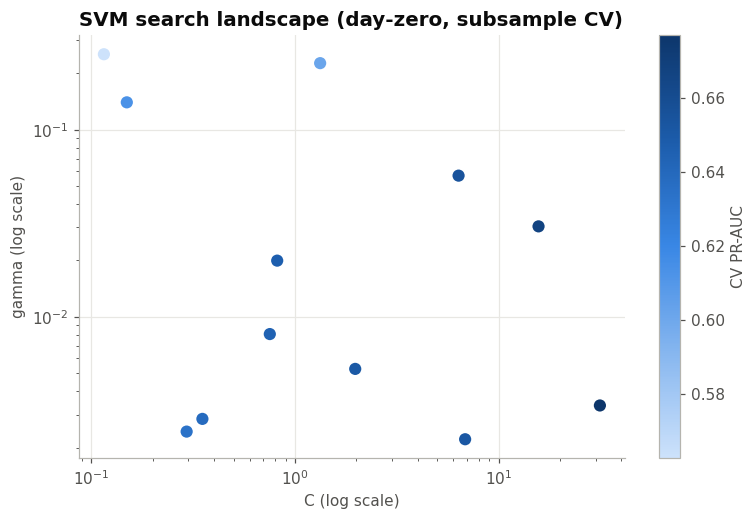

,mean_test_pr_auc,std_test_pr_auc,mean_fit_time,param_model__C,param_model__gamma
6,0.6770,0.0125,20.4518,31.4288,0.0034
1,0.6671,0.0163,23.9190,15.7030,0.0304
4,0.6548,0.0207,20.9609,6.3584,0.0568
10,0.6517,0.0099,19.2855,6.8479,0.0022
9,0.6509,0.0097,23.7346,1.9762,0.0053


In [11]:
results = pd.DataFrame(svm_searches["day_zero"].cv_results_)
fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(results["param_model__C"].astype(float), results["param_model__gamma"].astype(float),
                    c=results["mean_test_pr_auc"], cmap=SEQUENTIAL_CMAP, s=90, edgecolor="white", linewidth=1.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("C (log scale)")
ax.set_ylabel("gamma (log scale)")
ax.set_title("SVM search landscape (day-zero, subsample CV)", loc="left")
fig.colorbar(points, ax=ax, label="CV PR-AUC")
save_figure(fig, "search_landscape")
plt.show()
results.sort_values("rank_test_pr_auc")[["mean_test_pr_auc", "std_test_pr_auc", "mean_fit_time", "param_model__C", "param_model__gamma"]].head(5).round(4)

## 5. Final fit on full Train with probability calibration
`CalibratedClassifierCV` fits `CALIBRATION_FOLDS` SVCs on Train folds and calibrates
each on its held-out Train fold. Probabilities come out without touching Dev. This is
the slowest cell in the project.

In [12]:
import gc

svm_cards = {}
for variant, search in svm_searches.items():
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    svc = SVC(kernel="rbf", class_weight="balanced", cache_size=SVM_CACHE_MB, random_state=RANDOM_STATE, **best)
    calibrated = CalibratedClassifierCV(svc, method="sigmoid", n_jobs=CALIBRATION_N_JOBS,
                                        cv=StratifiedKFold(CALIBRATION_FOLDS, shuffle=True, random_state=RANDOM_STATE))

    # Transform Train and Dev once into contiguous float64 arrays (the dtype libsvm uses),
    # so the SVC fits do not each make their own converted copy. Same result as fitting the
    # Pipeline directly: the Pipeline also fits the preprocessor on all of Train first.
    preprocessor = load_preprocessor("linear", variant)
    Z_train = np.ascontiguousarray(preprocessor.fit_transform(X_train), dtype=np.float64)
    Z_dev = np.ascontiguousarray(preprocessor.transform(X_dev), dtype=np.float64)

    start = time.perf_counter()
    calibrated.fit(Z_train, y_train.to_numpy())
    fit_seconds = time.perf_counter() - start
    n_support = int(np.mean([c.estimator.n_support_.sum() for c in calibrated.calibrated_classifiers_]))
    print(f"[{variant}] full-Train fit {fit_seconds / 60:.1f} min, ~{n_support:,} support vectors per fold model")

    # Re-assemble the fitted steps so the saved model still takes raw feature frames.
    final_pipeline = Pipeline([("preprocess", preprocessor), ("model", calibrated)])
    dev_proba = calibrated.predict_proba(Z_dev)[:, 1]

    svm_cards[variant] = persist_model_outputs(
        model_key="svm_rbf", variant=variant, family="linear", pipeline=final_pipeline,
        fold_scores=fold_scores_from_search(search, CV_FOLDS),
        dev_proba=dev_proba,
        best_params=search.best_params_, imbalance_strategy="class_weight",
        fit_seconds=search.elapsed_seconds_ + fit_seconds, search=search, cv_rows=len(X_search),
        extra={"cv_on_subsample": True, "search_sample_size": len(X_search),
               "probability_method": f"CalibratedClassifierCV(sigmoid, cv={CALIBRATION_FOLDS}) on Train",
               "mean_support_vectors": n_support, "support_vector_fraction": n_support / (len(X_train) * (CALIBRATION_FOLDS - 1) / CALIBRATION_FOLDS)},
    )

    del Z_train, Z_dev, calibrated, final_pipeline, dev_proba
    gc.collect()

[day_zero] full-Train fit 5.4 min, ~21,701 support vectors per fold model
[svm_rbf__day_zero] CV PR-AUC 0.6770 ± 0.0140 | Dev PR-AUC 0.6887


## 6. Sanity check: subsample CV vs full-Train Dev score
If Dev PR-AUC is close to (or above) the subsample CV estimate, the subsample did not
distort the hyper-parameter choice. A large drop would call for a bigger
`SEARCH_SAMPLE_SIZE`.

In [13]:
pd.DataFrame({
    variant: {"subsample_cv_pr_auc": card["cv_summary"]["pr_auc"]["mean"],
              "subsample_cv_std": card["cv_summary"]["pr_auc"]["std"],
              "full_train_dev_pr_auc": card["dev_quick"]["pr_auc"],
              "support_vector_fraction": card["support_vector_fraction"]}
    for variant, card in svm_cards.items()
}).T.round(4)

,subsample_cv_pr_auc,subsample_cv_std,full_train_dev_pr_auc,support_vector_fraction
day_zero,0.677,0.014,0.6887,0.5337


## 7. Hand-off summary
- `svm_rbf__day_zero` is logged. Its card is flagged `cv_on_subsample: true`, so notebook 11 reports
  its CV row with that caveat and leaves it out of fold-paired significance tests (different folds).
